# BigBird: Transformers for Longer Sequences

A short research overview with attention diagrams, a theoretical scaling graph, and a practical Python example.

## Introduction

BigBird is a Transformer model that was introduced by Google Research mainly to deal with long sequences.
The main problem with normal Transformers such as BERT is the self-attention mechanism. In BERT, every token attends to every other token in the sequence. This works well, but it becomes very expensive when the sequence gets longer.

This means that if the sequence becomes much longer, the number of attention calculations increases very quickly.
BigBird tries to solve this problem by using sparse attention instead of full attention.

## Why BigBird Was Needed

BERT usually works with a maximum sequence length of around 512 tokens.
This can be a problem for things like:
- long research papers
- legal documents
- long articles
- books
- long question-answering documents
- genomic sequences

For example, if we have 512 tokens, full attention calculates relationships between all of them.
If we increase the sequence to 4096 tokens, the attention matrix becomes much larger.
So BigBird was designed to allow Transformers to work with longer sequences without calculating every possible token-to-token relationship.

Instead of making every token attend to every other token, BigBird uses three types of attention:
1. Local attention (means that each token mainly attends to tokens close to it)
2. Random attention
3. Global attention

These three together allow BigBird to keep important information while reducing the amount of computation.

Also BigBird usually works with blocks of tokens instead of treating every sparse connection separately. (This is called block-sparse attention.)

### Visualizing the attention patterns

![**Figure 1.** Each square represents an allowed connection between two token blocks. A row shows the key blocks one query block can attend to. Local links stay near the diagonal; random links reach distant blocks; global rows and columns connect across the sequence. The combined mask is their union. This is an illustrative block pattern, not an extracted model attention map. [1]](attachment:attention_patterns.png)

**Figure 1.** Each square represents an allowed connection between two token blocks. A row shows the key blocks one query block can attend to. Local links stay near the diagonal; random links reach distant blocks; global rows and columns connect across the sequence. The combined mask is their union. This is an illustrative block pattern, not an extracted model attention map. [1]
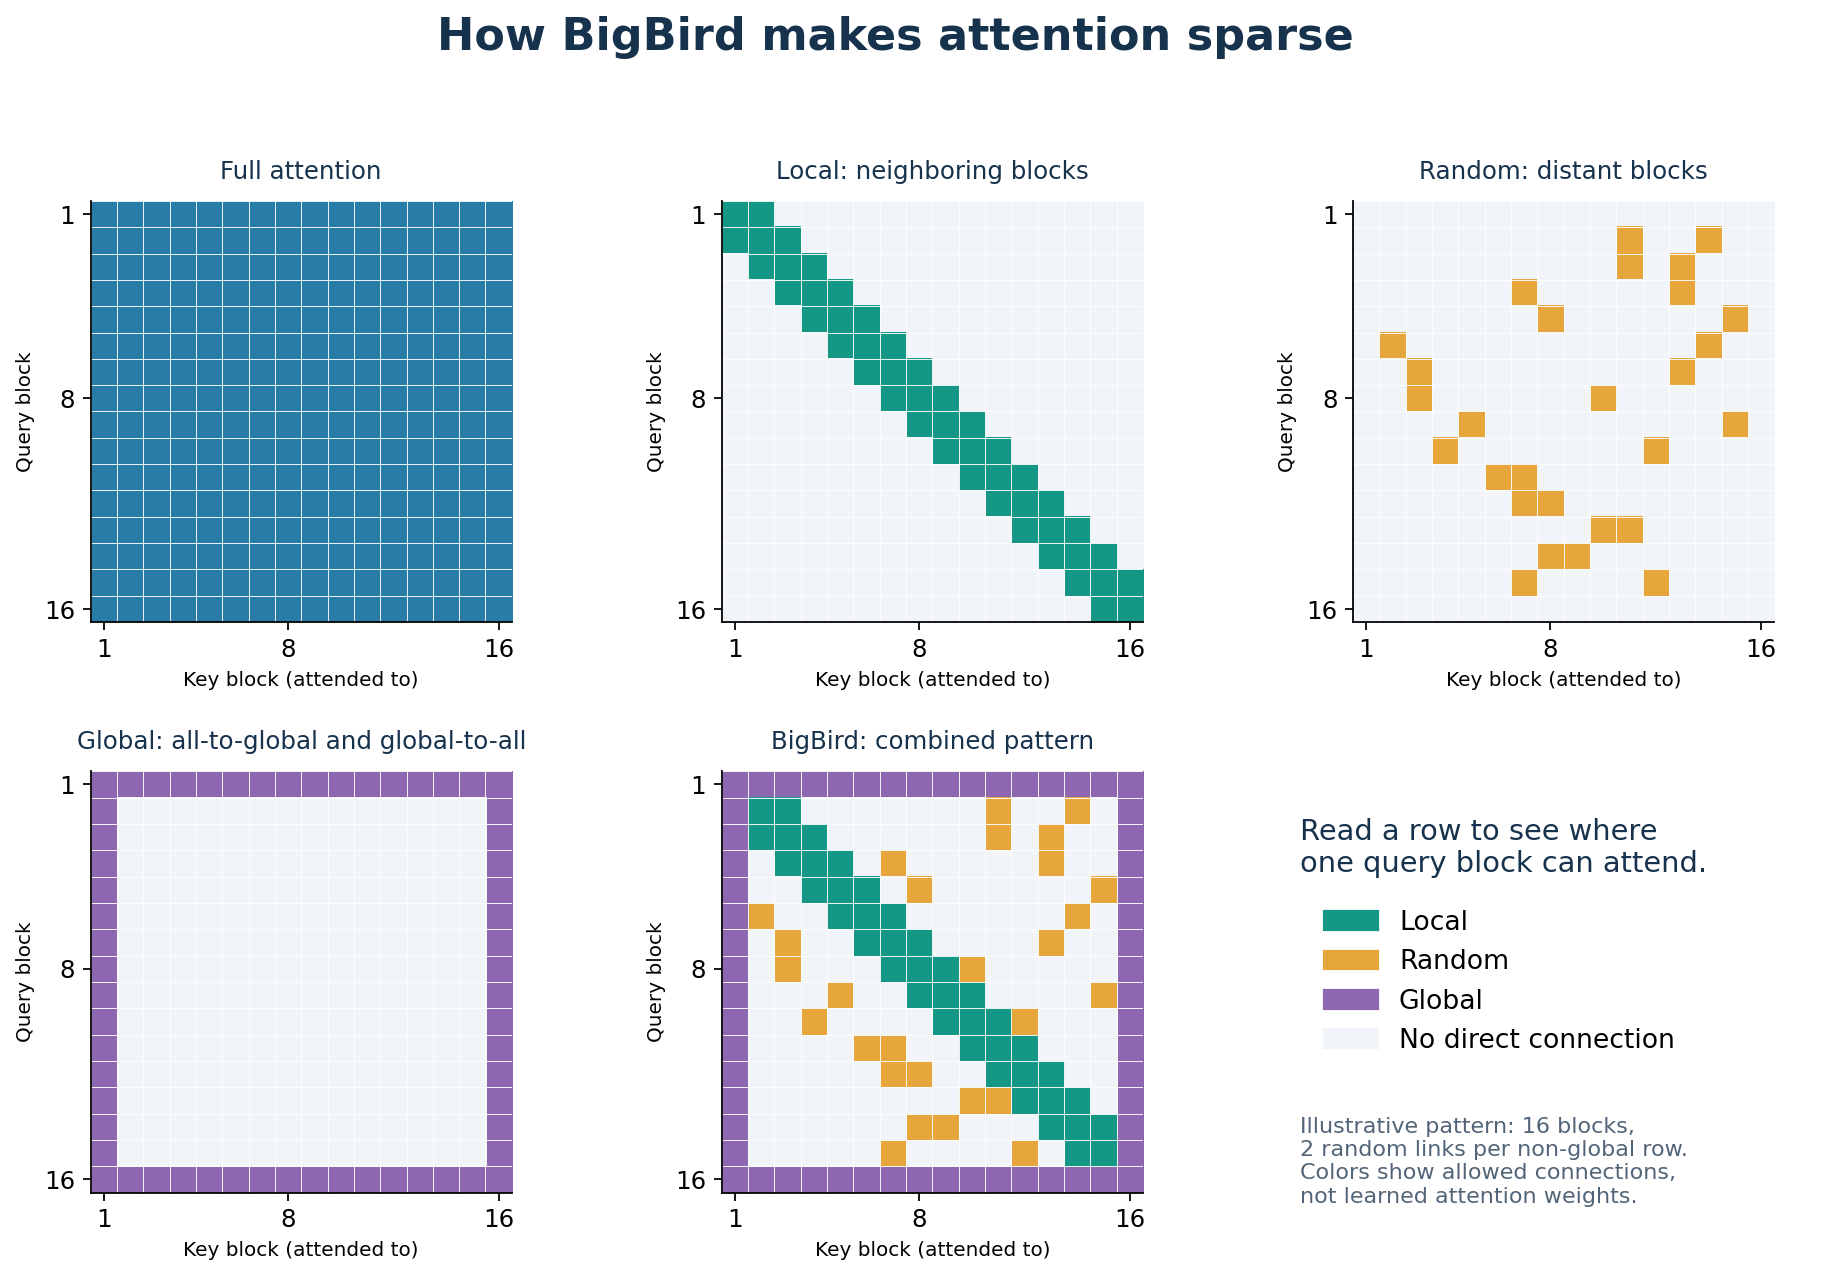

A block contains several neighboring tokens. For example, a block size of 64 groups 64 tokens together. Allowing one block to attend to another creates a dense token-to-token submatrix within that block pair. Sparse attention selects a subset of these block pairs. The figure uses two random links per non-global row for readability; the practical example uses the checkpoint’s settings.

## Computational Complexity

Full self-attention computes interactions between every pair of tokens. Its attention cost grows as $O(n^2)$ with sequence length $n$.

BigBird uses a sparse set of local, random, and global connections. Its attention cost grows as $O(n)$ **when the local window, random connections, global tokens, and block size remain fixed**. This refers to scaling with sequence length, holding model dimensions fixed. [1]

For example, increasing the input from 512 to 4,096 tokens makes the sequence 8 times longer. The quadratic term grows by $8^2 = 64$ times, while the linear term grows by 8 times.

### Visual comparison: theoretical scaling

The following short code cell generates the graph. Each curve is normalized independently to 1 at 512 tokens, so it compares **growth rates**, not absolute computation. It does not measure inference time, memory consumption, or accuracy. The 8,192-token point illustrates the mathematical trend; it does not imply that the checkpoint below supports that input length.

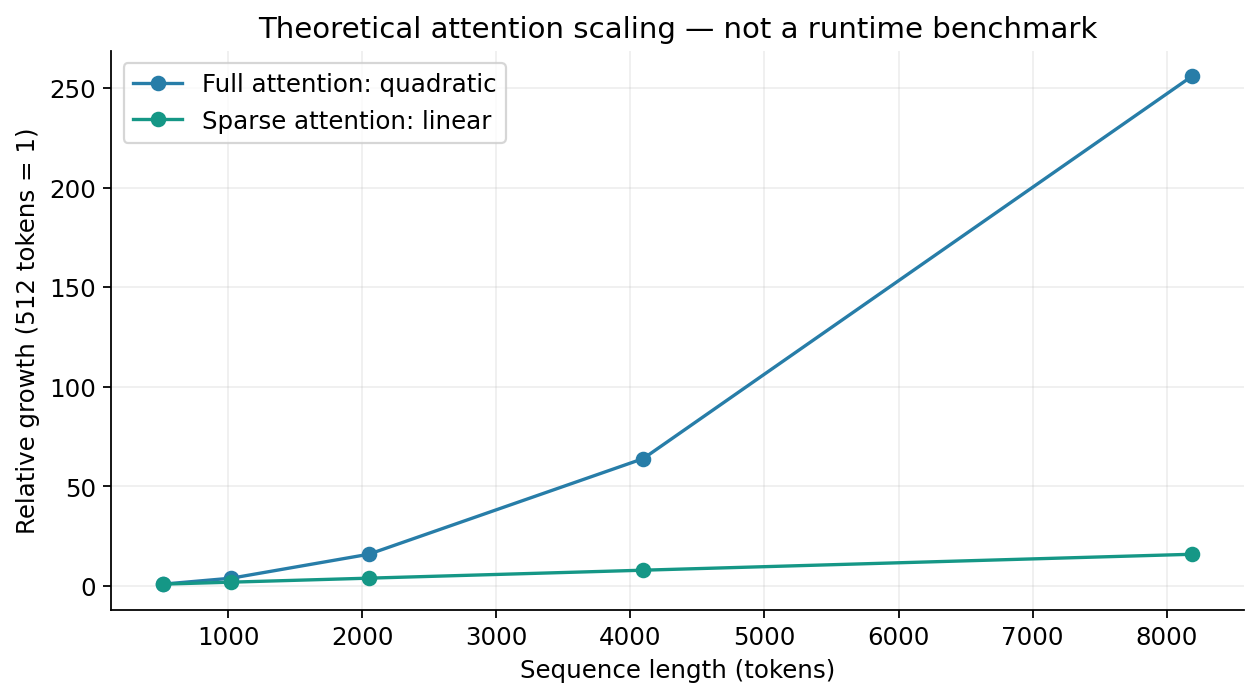

In [1]:
import numpy as np
import matplotlib.pyplot as plt

n = np.array([512, 1024, 2048, 4096, 8192])
full = (n / 512) ** 2  # quadratic growth, normalized at 512 tokens
sparse = n / 512       # linear growth, normalized at 512 tokens

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(n, full, "o-", label="Full attention: quadratic", color="#277da8")
ax.plot(n, sparse, "o-", label="Sparse attention: linear", color="#159786")
ax.set(xlabel="Sequence length (tokens)", ylabel="Relative growth (512 tokens = 1)",
       title="Theoretical attention scaling — not a runtime benchmark")
ax.legend()
ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()


**Figure 2.** The quadratic curve rises much faster as the input grows. Actual speed and memory depend on implementation, hardware, model size, and input length; this plot is not evidence of a specific measured speedup.

### BigBird Architecture



![**Figure 3.** Simplified BigBird encoder. Each residual path adds a sublayer’s input back to its output before LayerNorm. The encoder layer is repeated to build the model. [1]](attachment:architecture.png)

**Figure 3.** Simplified BigBird encoder. Each residual path adds a sublayer’s input back to its output before LayerNorm. The encoder layer is repeated to build the model. [1]
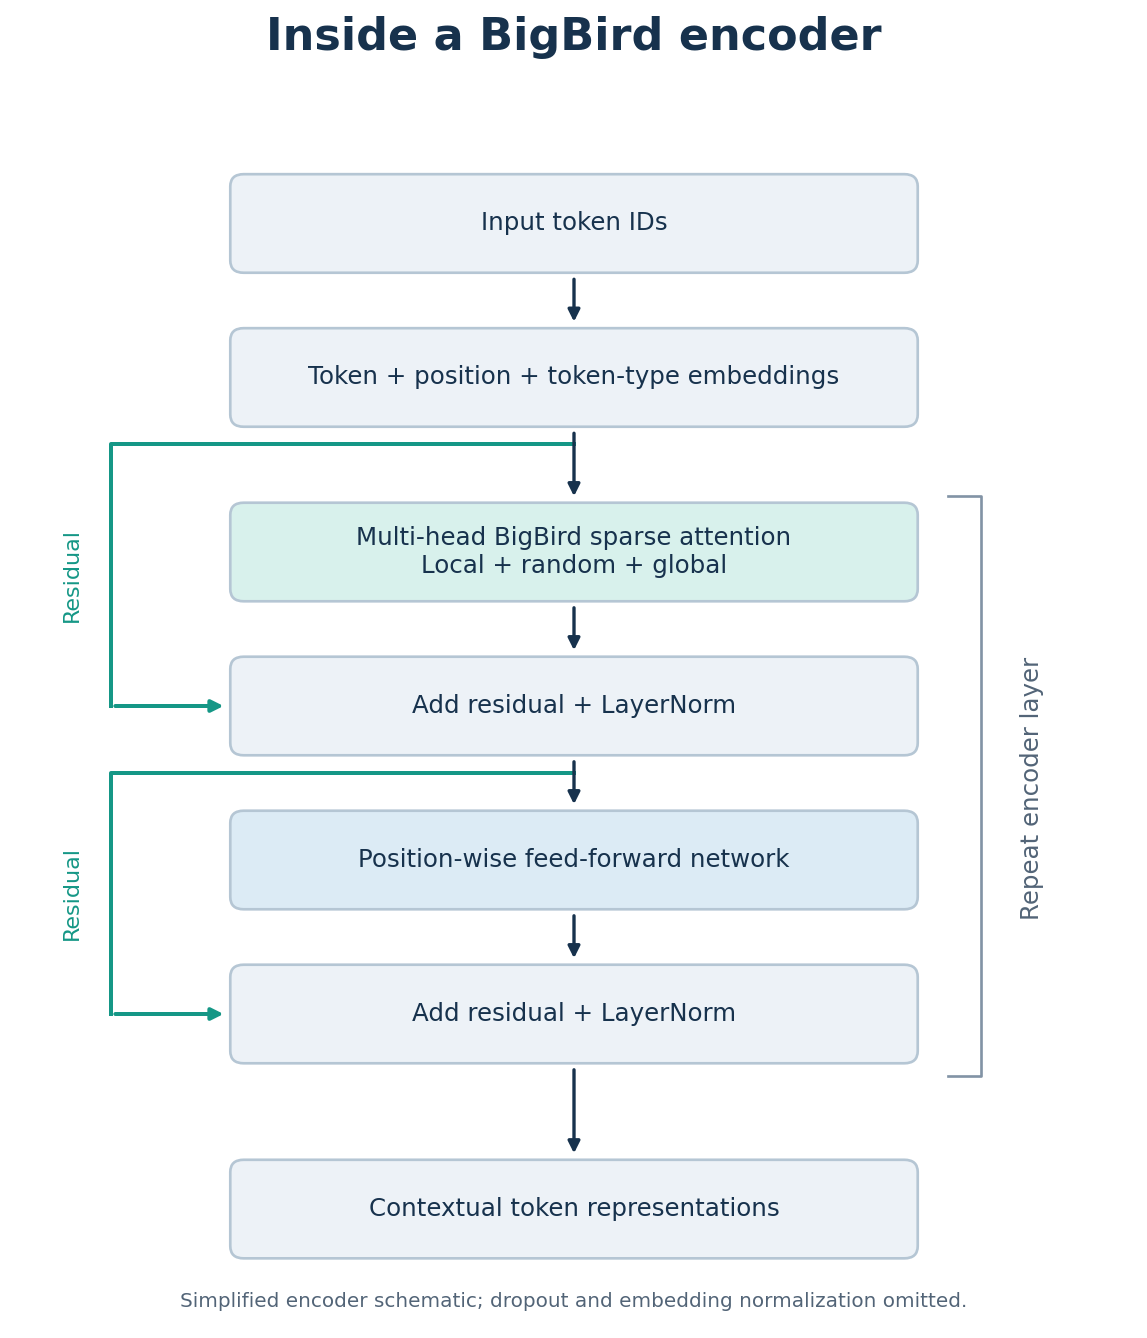

### BigBird vs BERT


| Feature | BERT | BigBird |
|---|---|---|
| Attention | Full attention | Sparse attention |
| Complexity | \(O(n^2)\) | About \(O(n)\) |
| Sequence length | Usually 512 | Can support much longer sequences |
| Local attention | Not specifically needed | Yes |
| Global attention | All tokens already interact | Yes |
| Random attention | No | Yes |
| Best use | Normal-sized text | Long documents |

### BigBird vs Longformer

Both models use sparse attention for long sequences. **Longformer combines sliding-window local attention with selected global attention; BigBird also includes random connections.** This is the main pattern difference, but the implementations are not otherwise identical. [1, 2]

| Attention component | Longformer | BigBird |
|---|---|---|
| Local / sliding window | Yes | Yes |
| Global | Yes | Yes |
| Random | Not part of its standard pattern | Yes |

Both have linear attention scaling in sequence length when their respective sparsity settings are held fixed.

### Applications of BigBird
BigBird is useful when the model needs to understand a large amount of text at the same time.
Some examples are:
- long-document classification
- question answering over long documents
- summarization
- research papers
- legal documents
- large reports
- genomic and DNA sequences

For example, if the answer to a question is near the end of a very long document, BigBird can process much more of the document at once compared with normal BERT.

### Advantages
- It can process much longer sequences than BERT.
- It reduces attention complexity from quadratic to approximately linear.
- It still keeps both local and long-distance information.
- Random attention helps connect distant parts of the document.
- Global attention allows important tokens to communicate with the whole sequence.
- It works well for long-document NLP tasks.

### Limitations
First, sparse attention means that not every token directly attends to every other token.
Because of this, full attention can still be better when the sequence is short and computational cost is not a problem.
Also, BigBird is more complicated than normal BERT attention because the sparse attention pattern must be managed.
For relatively short sequences, using BigBird may not give much advantage because BERT's normal attention is already manageable.
Its block-sparse implementation can also have restrictions related to block size and sequence length.

### Performance
The main advantage of BigBird is not simply that it is always more accurate than BERT.
Its main advantage is that it can process much more context.

BigBird showed strong results in long-document tasks such as question answering and summarization.
It was also tested on genomic data, showing that the architecture is useful outside normal text processing as well.

## Practical Example: Processing a Long Input

This example loads pretrained weights and runs one forward pass. It returns contextual vectors for the input tokens; it does not train the model, classify the document, or generate a summary. [3]

**Setup:** if needed, run `%pip install torch transformers sentencepiece numpy matplotlib` in a separate notebook cell, then restart the kernel if requested. Internet is needed for the first model and tokenizer download. The code runs on CPU by default.

We use 1,024 tokens, a multiple of the default 64-token block size, to demonstrate block-sparse attention. The selected checkpoint supports up to 4,096 positions. [3, 4]

**Execution note:** the plotting cell above was run and its output is saved. The pretrained-model cell below has been syntax-checked but has not been executed in the preparation environment, where PyTorch and Transformers were unavailable. Run it locally to obtain its actual output.

In [ ]:
import torch
from transformers import AutoTokenizer, BigBirdModel

checkpoint = "google/bigbird-roberta-base"
tokenizer = AutoTokenizer.from_pretrained(checkpoint)
model = BigBirdModel.from_pretrained(checkpoint, attention_type="block_sparse")
model.eval()

# Repetition creates a long input for a shape demonstration, not an evaluation.
text = "BigBird uses sparse attention to process long documents. " * 300
inputs = tokenizer(text, return_tensors="pt", truncation=True,
                   max_length=1024, padding="max_length")

with torch.no_grad():
    outputs = model(**inputs)

print("Input shape:", tuple(inputs["input_ids"].shape))
print("Output shape:", tuple(outputs.last_hidden_state.shape))
print("Attention type:", model.attention_type)


### Understanding the output

With the selected checkpoint, the **expected shapes** are:

- Input: `(1, 1024)` — one sequence containing 1,024 token positions.
- Output: `(1, 1024, 768)` — one contextual vector with 768 values for each position.
- Attention type: `block_sparse`.

These are expected values from the input settings and checkpoint configuration, **not a recorded model run**. The hidden-state dimensions describe the representations; they are not classification probabilities. [3, 4]

`model.eval()` switches to evaluation behavior, while `torch.no_grad()` disables gradient tracking. Repeating the sentence makes the example easy to run with a long input; it does not establish model quality.

## References

1. Zaheer et al. (2020). *Big Bird: Transformers for Longer Sequences*. NeurIPS. [Paper](https://arxiv.org/abs/2007.14062).
2. Beltagy, Peters, and Cohan (2020). *Longformer: The Long-Document Transformer*. [Paper](https://arxiv.org/abs/2004.05150).
3. Hugging Face. *BigBird documentation*. [Model usage, implementation notes, and output shapes](https://huggingface.co/docs/transformers/en/model_doc/big_bird).
4. Google. *bigbird-roberta-base configuration*. [Checkpoint configuration](https://huggingface.co/google/bigbird-roberta-base/blob/main/config.json).
